# Online Retail Data Analysis

**Project type:** Exploratory Data Analysis (EDA)  
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn  

## Business objective
Explore online retail transactions to understand sales trends, top-performing products, and important markets, then provide practical business recommendations.

## Important data-handling rule
This notebook keeps the original/raw dataset unchanged and creates a separate cleaned dataset for analysis. Put your original CSV file in the same folder as this notebook, or update the file path in the next code cell.

## 1. Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')

print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load the raw dataset

Change `file_path` to the exact name of your original CSV file if needed. For example, use `Path('OnlineRetail.csv')` if that is your filename.

In [ ]:
raw_data = pd.read_csv("../data/raw/OnlineRetail.csv", encoding='ISO-8859-1')
clean_data = raw_data.copy(deep=True)  # Work on a copy; raw_data remains unchanged

print('Raw dataset loaded.')
print('Rows:', len(raw_data))
print('Columns:', len(raw_data.columns))
display(raw_data.head())

Raw dataset loaded.
Rows: 541909
Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


## 3. Understand the data

In [13]:
# Display the number of columns and rows
print("Dataset shape:",raw_data.shape)

# Display column names
print("Column names:",raw_data.columns.tolist())

# Display dataset information
print("Data Information:",raw_data.info())

# 
display(raw_data.describe(include='all').T)

# Count missing values in eavh columns
print('Missing values by column:')
display(raw_data.isna().sum().sort_values(ascending=False).to_frame('MissingValues'))

# Count duplicate rows
print('Exact duplicate rows:', df.duplicated().sum())

# Display dataset column type
print("Data column type:", raw_data.dtypes)

Dataset shape: (541909, 8)
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB
Data Information: None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4219,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","1,713.60","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values by column:


,MissingValues
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


Exact duplicate rows: 5268
Data column type: InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object


## 4. Clean the data

This section standardizes column names and data types, removes exact duplicate rows, and removes records that cannot support basic sales analysis because key transaction fields are missing. Missing customer IDs and product descriptions are retained where possible because those records can still contribute to sales totals.

In [14]:
# Copy the Raw dataset
clean_data = raw_data.copy(deep=True) 

# Standardize column names by removing surrounding spaces
clean_data.columns = clean_data.columns.str.strip()

# Check that the expected Online Retail columns are available
required_columns = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
missing_columns = [col for col in required_columns if col not in clean_data.columns]
if missing_columns:
    raise ValueError(f'Missing expected columns: {missing_columns}. Check your CSV column names.')

# Remove exact duplicate rows
rows_before_duplicates = len(clean_data)
clean_data = clean_data.drop_duplicates().copy()
duplicates_removed = rows_before_duplicates - len(clean_data)

# Convert fields to appropriate types
clean_data['InvoiceNo'] = clean_data['InvoiceNo'].astype('string').str.strip()
clean_data['StockCode'] = clean_data['StockCode'].astype('string').str.strip()
clean_data['Description'] = clean_data['Description'].astype('string').str.strip()
clean_data['Country'] = clean_data['Country'].astype('string').str.strip()
clean_data['Quantity'] = pd.to_numeric(clean_data['Quantity'], errors='coerce')
clean_data['UnitPrice'] = pd.to_numeric(clean_data['UnitPrice'], errors='coerce')
clean_data['CustomerID'] = pd.to_numeric(clean_data['CustomerID'], errors='coerce')
clean_data['InvoiceDate'] = pd.to_datetime(clean_data['InvoiceDate'], errors='coerce')

# Remove rows missing essential transaction fields
rows_before_required = len(clean_data)
clean_data = clean_data.dropna(subset=['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'InvoiceDate', 'Country']).copy()
rows_missing_required_removed = rows_before_required - len(clean_data)

# Add analysis fields
clean_data['SaleValue'] = clean_data['Quantity'] * clean_data['UnitPrice']
clean_data['IsCancellation'] = clean_data['InvoiceNo'].str.upper().str.startswith('C')
clean_data['YearMonth'] = clean_data['InvoiceDate'].dt.to_period('M').astype(str)
clean_data['Year'] = clean_data['InvoiceDate'].dt.year

# Separate cleaned dataset variable; raw_data is still unchanged
cleaned_df = clean_data.copy()

print(f'Exact duplicate rows removed: {duplicates_removed:,}')
print(f'Rows missing essential transaction fields removed: {rows_missing_required_removed:,}')
print('Raw dataset shape:', raw_data.shape)
print('Cleaned dataset shape:', clean_data.shape)
display(clean_data.head())

Exact duplicate rows removed: 5,268
Rows missing essential transaction fields removed: 0
Raw dataset shape: (541909, 8)
Cleaned dataset shape: (536641, 12)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SaleValue,IsCancellation,YearMonth,Year
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,15.30,False,2010-12,2010
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,False,2010-12,2010
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,22.00,False,2010-12,2010
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,False,2010-12,2010
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,20.34,False,2010-12,2010


## 5. Validate the cleaned dataset

In [15]:
quality_summary = pd.DataFrame({
    'Metric': [
        'Rows in raw dataset', 'Rows in cleaned dataset', 'Missing descriptions',
        'Missing customer IDs', 'Missing invoice dates', 'Missing quantities',
        'Missing unit prices', 'Duplicate rows remaining', 'Negative quantity rows',
        'Cancellation rows', 'Unique invoices', 'Unique customers', 'Unique countries'
    ],
    'Value': [
        len(raw_data), len(clean_data), clean_data['Description'].isna().sum(),
        clean_data['CustomerID'].isna().sum(), clean_data['InvoiceDate'].isna().sum(),
        clean_data['Quantity'].isna().sum(), clean_data['UnitPrice'].isna().sum(),
        clean_data.duplicated().sum(), (clean_data['Quantity'] < 0).sum(),
        clean_data['IsCancellation'].sum(), clean_data['InvoiceNo'].nunique(),
        clean_data['CustomerID'].nunique(), clean_data['Country'].nunique()
    ]
})
display(quality_summary)

,Metric,Value
0,Rows in raw dataset,541909
1,Rows in cleaned dataset,536641
2,Missing descriptions,1454
3,Missing customer IDs,135037
4,Missing invoice dates,0
5,Missing quantities,0
6,Missing unit prices,0
7,Duplicate rows remaining,0
8,Negative quantity rows,10587
9,Cancellation rows,9251


## 6. Key performance indicators (KPIs)

Sales here means **net sales**: `Quantity × UnitPrice`, so negative quantities reduce the total. Invoice counts can differ depending on whether cancellations are included; keep the chosen definition clear in the report.

In [16]:
total_rows = len(clean_data)
net_sales = clean_data['SaleValue'].sum()
positive_sales = clean_data.loc[clean_data['SaleValue'] > 0, 'SaleValue'].sum()
negative_sales = clean_data.loc[clean_data['SaleValue'] < 0, 'SaleValue'].sum()
unique_invoices = clean_data['InvoiceNo'].nunique()
unique_customers = clean_data['CustomerID'].nunique()
unique_countries = clean_data['Country'].nunique()

kpis = pd.DataFrame({
    'KPI': ['Cleaned transaction rows', 'Net sales', 'Positive sales', 'Negative sales / returns',
            'Unique invoice numbers', 'Unique customers with ID', 'Unique countries'],
    'Value': [total_rows, net_sales, positive_sales, negative_sales,
              unique_invoices, unique_customers, unique_countries]
})
display(kpis)

,KPI,Value
0,Cleaned transaction rows,"536,641.00"
1,Net sales,"9,726,006.95"
2,Positive sales,"10,642,110.80"
3,Negative sales / returns,"-916,103.85"
4,Unique invoice numbers,"25,900.00"
5,Unique customers with ID,"4,372.00"
6,Unique countries,38.00


## 7. Monthly net sales trend

,YearMonth,SaleValue
0,2010-12,"746,723.61"
1,2011-01,"558,448.56"
2,2011-02,"497,026.41"
3,2011-03,"682,013.98"
4,2011-04,"492,367.84"
5,2011-05,"722,094.10"
6,2011-06,"689,977.23"
7,2011-07,"680,156.99"
8,2011-08,"681,386.46"
9,2011-09,"1,017,596.68"


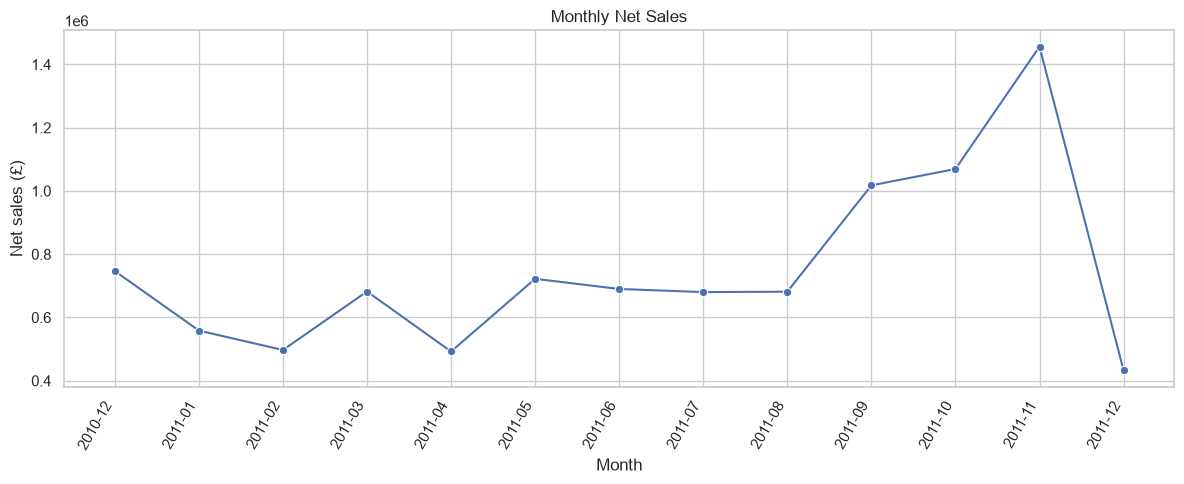

In [17]:
monthly_sales = (
    clean_data.groupby('YearMonth', as_index=False)['SaleValue']
    .sum()
    .sort_values('YearMonth')
)
display(monthly_sales)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='YearMonth', y='SaleValue', marker='o')
plt.title('Monthly Net Sales')
plt.xlabel('Month')
plt.ylabel('Net sales (£)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

## 8. Top 10 products by net sales

,Description,SaleValue
1087,DOTCOM POSTAGE,"206,245.48"
2900,REGENCY CAKESTAND 3 TIER,"164,459.49"
3903,WHITE HANGING HEART T-LIGHT HOLDER,"99,612.42"
2457,PARTY BUNTING,"98,243.88"
1851,JUMBO BAG RED RETROSPOT,"92,175.79"
2787,RABBIT NIGHT LIGHT,"66,661.63"
2737,POSTAGE,"66,230.64"
2426,PAPER CHAIN KIT 50'S CHRISTMAS,"63,715.24"
234,ASSORTED COLOUR BIRD ORNAMENT,"58,792.42"
762,CHILLI LIGHTS,"53,746.66"


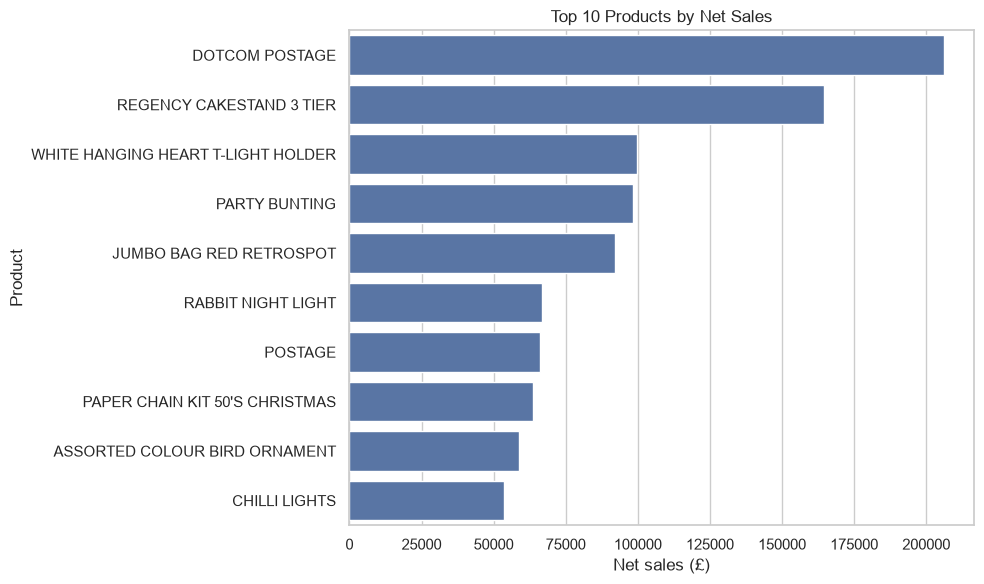

In [18]:
product_sales = (
    clean_data.dropna(subset=['Description'])
    .groupby('Description', as_index=False)['SaleValue'].sum()
    .sort_values('SaleValue', ascending=False)
    .head(10)
)
display(product_sales)

plt.figure(figsize=(10, 6))
sns.barplot(data=product_sales, x='SaleValue', y='Description')
plt.title('Top 10 Products by Net Sales')
plt.xlabel('Net sales (£)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

## 9. Top 10 countries by net sales

,Country,SaleValue
36,United Kingdom,"8,167,128.18"
24,Netherlands,"284,661.54"
10,EIRE,"262,993.38"
14,Germany,"221,509.47"
13,France,"197,317.11"
0,Australia,"137,009.77"
33,Switzerland,"56,363.05"
31,Spain,"54,756.03"
3,Belgium,"40,910.96"
32,Sweden,"36,585.41"


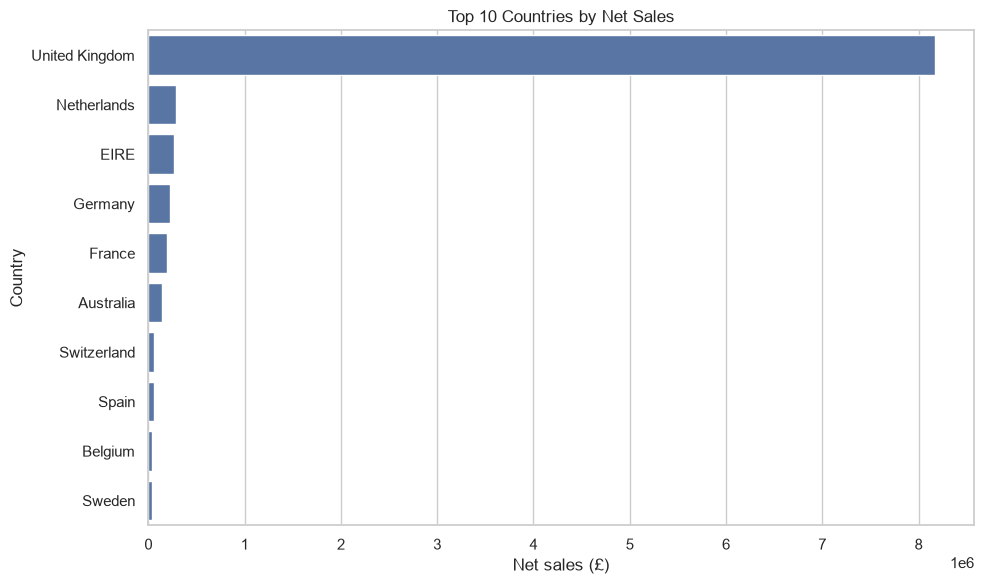

In [19]:
country_sales = (
    clean_data.groupby('Country', as_index=False)['SaleValue'].sum()
    .sort_values('SaleValue', ascending=False)
    .head(10)
)
display(country_sales)

plt.figure(figsize=(10, 6))
sns.barplot(data=country_sales, x='SaleValue', y='Country')
plt.title('Top 10 Countries by Net Sales')
plt.xlabel('Net sales (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

## 10. Cancellation and negative-quantity review

In [20]:
cancellation_summary = pd.DataFrame({
    'Metric': ['Cancellation rows (InvoiceNo begins with C)', 'Negative quantity rows',
               'Negative sales value', 'Positive sales value', 'Net sales value'],
    'Value': [
        int(clean_data['IsCancellation'].sum()),
        int((clean_data['Quantity'] < 0).sum()),
        clean_data.loc[clean_data['SaleValue'] < 0, 'SaleValue'].sum(),
        clean_data.loc[clean_data['SaleValue'] > 0, 'SaleValue'].sum(),
        clean_data['SaleValue'].sum()
    ]
})
display(cancellation_summary)

cancellation_sales = (
    clean_data.groupby('IsCancellation', as_index=False)['SaleValue'].sum()
)
display(cancellation_sales)

,Metric,Value
0,Cancellation rows (InvoiceNo begins with C),"9,251.00"
1,Negative quantity rows,"10,587.00"
2,Negative sales value,"-916,103.85"
3,Positive sales value,"10,642,110.80"
4,Net sales value,"9,726,006.95"


,IsCancellation,SaleValue
0,False,"10,619,986.68"
1,True,"-893,979.73"


## 11. Business insights and recommendations

Use the outputs above to write evidence-based findings. Avoid assuming a product or country is performing well based on one metric alone.

Suggested questions:
- Which month had the highest net sales, and which had the lowest?
- Which products contributed the most net sales?
- How concentrated are sales in the top country compared with other countries?
- How large are negative sales and cancellation records relative to positive sales?
- Are the first or last months partial periods that could make comparisons misleading?

### Recommendations template
1. **Sales planning:** Use monthly trends to plan stock and staffing, while checking for incomplete months.
2. **Product strategy:** Review top products for availability and margins before prioritizing them.
3. **Market strategy:** Compare the leading country with smaller markets and investigate growth opportunities.
4. **Returns monitoring:** Track negative quantities and cancellation invoices separately from ordinary sales.
5. **Data quality:** Continue monitoring missing customer IDs and product descriptions.

## 12. Export the cleaned dataset and summary tables

In [21]:
# Export a separate cleaned file; do not overwrite the original CSV
cleaned_output = Path('Cleaned_OnlineRetail.csv')
cleaned_df.to_csv(cleaned_output, index=False)

monthly_sales.to_csv('Monthly_Net_Sales.csv', index=False)
product_sales.to_csv('Top_10_Products.csv', index=False)
country_sales.to_csv('Top_10_Countries.csv', index=False)

print(f'Cleaned dataset saved to: {cleaned_output.resolve()}')
print('Summary tables exported successfully.')

Cleaned dataset saved to: C:\Users\USER\OneDrive\Desktop\AnalystLab-Week1-2\notebooks\Cleaned_OnlineRetail.csv
Summary tables exported successfully.


## Project conclusion

This notebook preserves the raw data, creates a separate cleaned dataset, calculates core retail KPIs, reviews monthly sales, compares products and countries, and examines cancellation/negative-sale records. Final conclusions should refer to the actual outputs produced when all cells run successfully.